[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cauasantoslt/CardioIA/blob/main/Fase4/notebooks/02_classificacao_cnn_transfer_learning.ipynb)

# FIAP — Inteligência Artificial (PBL · 2º Ano)
## CardioIA: A Nova Era da Cardiologia Inteligente
### Fase 4 (Parte 2) — Classificação de Imagens Médicas de ECG com CNN do Zero e Transfer Learning (ResNet18)

* **Aluno:** Cauã Santos — **RM:** 566599
* **Abordagens Comparadas:**
  1. **CardioCNN (Treinada do Zero):** Rede Convolucional de 4 blocos (`Conv2d -> BatchNorm -> ReLU -> MaxPool`) + *Dual Global Pooling* (Avg + Max) sobre tensores `(1, 128, 128)` binarizados.
  2. **ResNet18 (Transfer Learning — ImageNet-1K):** Treinamento em dois estágios (*Feature Extraction* com backbone congelado + *Fine-Tuning* com learning rate diferencial) sobre tensores `(3, 224, 224)` binarizados.
* **Avaliação Clínica:** Acurácia, Precisão, Recall, F1-Score (Macro e por classe), Matriz de Confusão, Explicabilidade visual via **Grad-CAM** e **Protótipo Interativo de Classificação**.
            

In [1]:
import os
import sys
import json
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/CardioIA").exists():
    os.system("git clone https://github.com/cauasantoslt/CardioIA.git /content/CardioIA")

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path("/content/CardioIA")]
PROJECT_ROOT = next((p for p in candidates if (p / "Fase1" / "assets" / "images" / "ECG_Image_data").exists()), None)
assert PROJECT_ROOT is not None, "Repositório CardioIA não encontrado."

SRC_DIR = PROJECT_ROOT / "Fase4" / "src"
MODELS_DIR = PROJECT_ROOT / "Fase4" / "models"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader

from preprocessamento import CLASSES, CLASS_INFO, auditar_e_organizar_dataset, preprocessar_imagem_ecg
from modelos import (
    CardioCNN,
    ResNet18ECG,
    ECGDataset,
    GradCAM,
    CardioPredictor,
    array_para_tensor,
    renderizar_gradcam_sobreposto,
)
from treinar_e_avaliar import avaliar_modelo, treinar_cnn_do_zero, treinar_resnet18_transfer

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Dispositivo: {device}")
            

PyTorch 2.14.1+cpu | Dispositivo: cpu


---
## 1. Carregamento do Dataset Organizado e Arquiteturas

Para reprodutibilidade rápida no notebook, a flag `RETREINAR_DO_ZERO = False` carrega os checkpoints já treinados e auditados em `Fase4/models/` (gerados por `Fase4/src/treinar_e_avaliar.py`). Altere para `True` caso deseje reexecutar todas as épocas do treinamento diretamente no Google Colab com GPU.
            

In [2]:
df, prep_summary = auditar_e_organizar_dataset()
print("Splits carregados:", prep_summary["splits"])

RETREINAR_DO_ZERO = False  # Altere para True para retreinar no Colab (GPU/CPU)

cnn_ckpt = MODELS_DIR / "cnn_scratch_ecg.pt"
res_ckpt = MODELS_DIR / "resnet18_transfer_ecg.pt"
meta_path = MODELS_DIR / "metadata_modelos.json"

if RETREINAR_DO_ZERO or not (cnn_ckpt.exists() and res_ckpt.exists() and meta_path.exists()):
    print("Iniciando treinamento completo das duas abordagens...")
    cnn_model, cnn_res, _ = treinar_cnn_do_zero(df, device=device, epochs=45, batch_size=24)
    res_model, res_res, _ = treinar_resnet18_transfer(df, device=device, epochs_stage1=8, epochs_stage2=24, batch_size=20)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(cnn_model.state_dict(), cnn_ckpt)
    torch.save(res_model.state_dict(), res_ckpt)
    history_cnn = cnn_res["history"]
    history_res = res_res["history"]
    best_ep_cnn = cnn_res["best_epoch"]
    best_ep_res = res_res["best_epoch"]
    s1_epochs = res_res["epochs_stage1"]
else:
    print("Carregando pesos treinados salvos em Fase4/models/...")
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    cnn_model = CardioCNN(num_classes=len(CLASSES), in_channels=1).to(device)
    cnn_model.load_state_dict(torch.load(cnn_ckpt, map_location=device, weights_only=True))
    res_model = ResNet18ECG(num_classes=len(CLASSES), pretrained=False).to(device)
    res_model.load_state_dict(torch.load(res_ckpt, map_location=device, weights_only=True))
    history_cnn = meta["models"]["cnn_scratch"]["history"]
    history_res = meta["models"]["resnet18_transfer"]["history"]
    best_ep_cnn = meta["models"]["cnn_scratch"]["best_epoch"]
    best_ep_res = meta["models"]["resnet18_transfer"]["best_epoch"]
    s1_epochs = meta["models"]["resnet18_transfer"]["epochs_stage1"]

print(f"Parâmetros CardioCNN (Do Zero):         {sum(p.numel() for p in cnn_model.parameters()):,}")
print(f"Parâmetros ResNet18 (Transfer Learning): {sum(p.numel() for p in res_model.parameters()):,}")
            

Splits carregados: {'train': 240, 'val': 60, 'test': 120}
Carregando pesos treinados salvos em Fase4/models/...
Parâmetros CardioCNN (Do Zero):         455,270
Parâmetros ResNet18 (Transfer Learning): 11,242,950


---
## 2. Curvas de Treinamento e Validação (Convergência das Duas Abordagens)
            

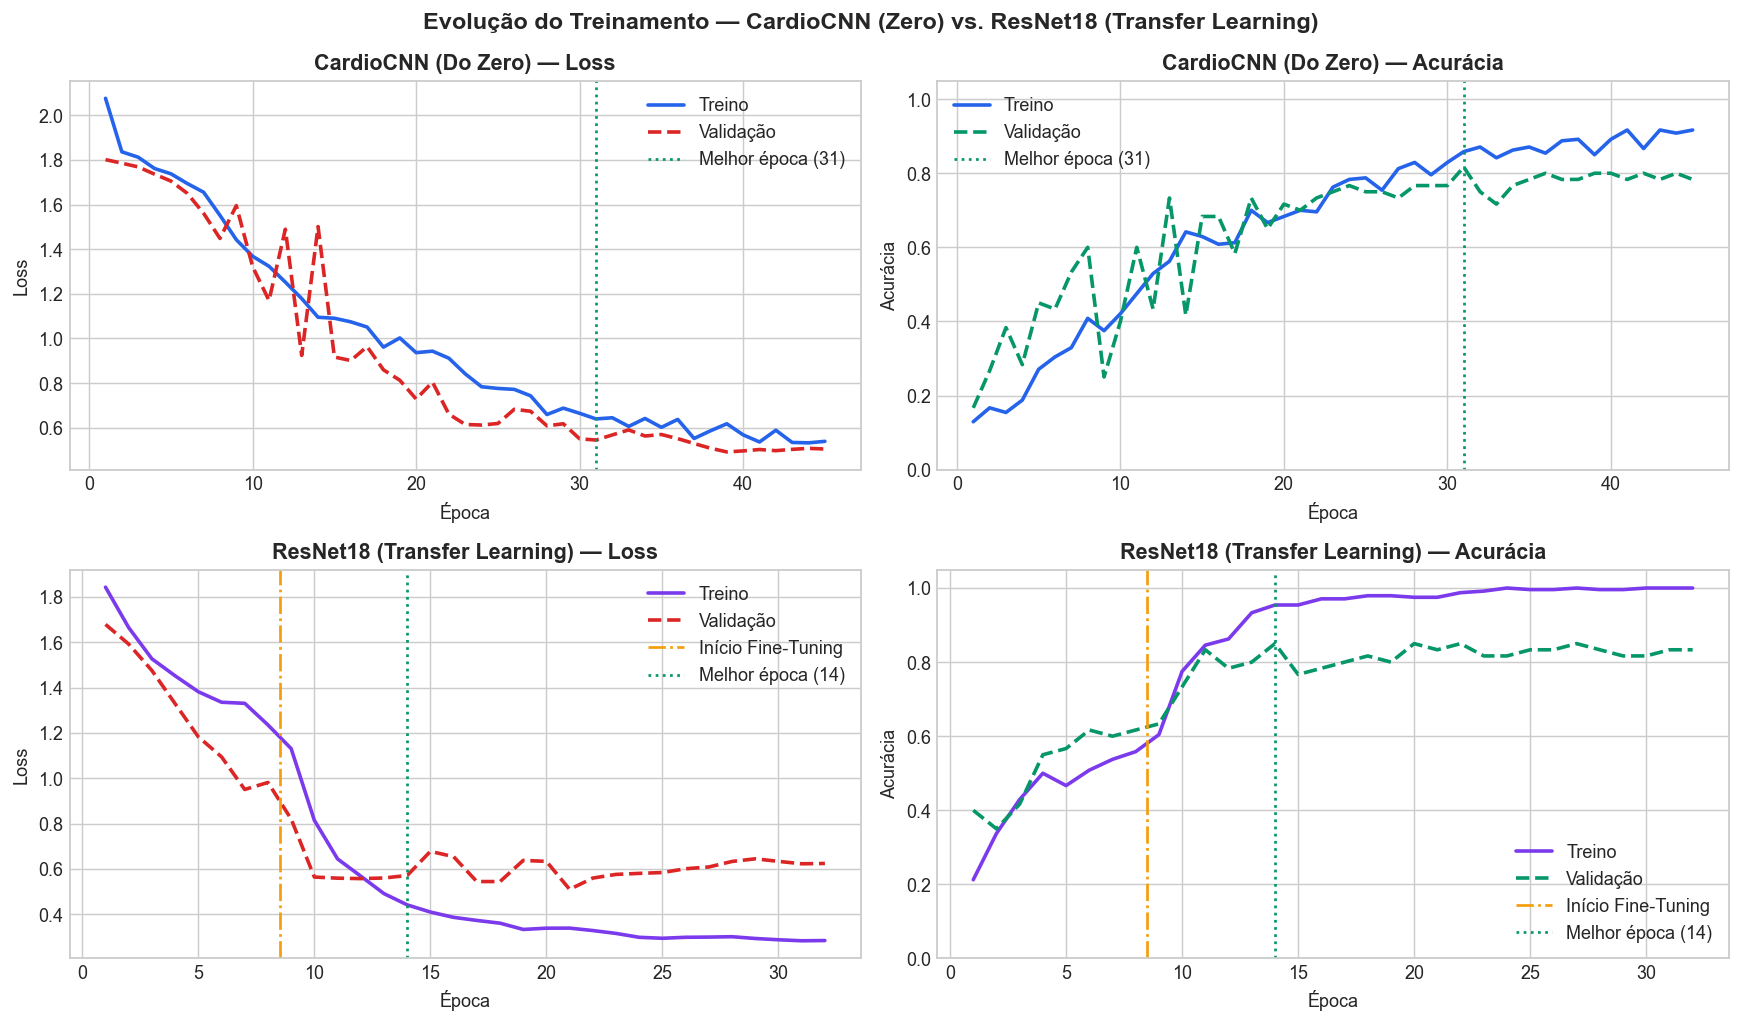

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8))
ep_c = np.arange(1, len(history_cnn["train_loss"]) + 1)
ep_r = np.arange(1, len(history_res["train_loss"]) + 1)

axes[0, 0].plot(ep_c, history_cnn["train_loss"], label="Treino", color="#2563eb", lw=2)
axes[0, 0].plot(ep_c, history_cnn["val_loss"], label="Validação", color="#dc2626", lw=2, ls="--")
axes[0, 0].axvline(best_ep_cnn, color="#059669", ls=":", label=f"Melhor época ({best_ep_cnn})")
axes[0, 0].set_title("CardioCNN (Do Zero) — Loss", fontweight="bold")
axes[0, 0].set_xlabel("Época"); axes[0, 0].set_ylabel("Loss"); axes[0, 0].legend()

axes[0, 1].plot(ep_c, history_cnn["train_acc"], label="Treino", color="#2563eb", lw=2)
axes[0, 1].plot(ep_c, history_cnn["val_acc"], label="Validação", color="#059669", lw=2, ls="--")
axes[0, 1].axvline(best_ep_cnn, color="#059669", ls=":", label=f"Melhor época ({best_ep_cnn})")
axes[0, 1].set_title("CardioCNN (Do Zero) — Acurácia", fontweight="bold")
axes[0, 1].set_xlabel("Época"); axes[0, 1].set_ylabel("Acurácia"); axes[0, 1].set_ylim(0, 1.05); axes[0, 1].legend()

axes[1, 0].plot(ep_r, history_res["train_loss"], label="Treino", color="#7c3aed", lw=2)
axes[1, 0].plot(ep_r, history_res["val_loss"], label="Validação", color="#dc2626", lw=2, ls="--")
axes[1, 0].axvline(s1_epochs + 0.5, color="#f59e0b", ls="-.", label="Início Fine-Tuning")
axes[1, 0].axvline(best_ep_res, color="#059669", ls=":", label=f"Melhor época ({best_ep_res})")
axes[1, 0].set_title("ResNet18 (Transfer Learning) — Loss", fontweight="bold")
axes[1, 0].set_xlabel("Época"); axes[1, 0].set_ylabel("Loss"); axes[1, 0].legend()

axes[1, 1].plot(ep_r, history_res["train_acc"], label="Treino", color="#7c3aed", lw=2)
axes[1, 1].plot(ep_r, history_res["val_acc"], label="Validação", color="#059669", lw=2, ls="--")
axes[1, 1].axvline(s1_epochs + 0.5, color="#f59e0b", ls="-.", label="Início Fine-Tuning")
axes[1, 1].axvline(best_ep_res, color="#059669", ls=":", label=f"Melhor época ({best_ep_res})")
axes[1, 1].set_title("ResNet18 (Transfer Learning) — Acurácia", fontweight="bold")
axes[1, 1].set_xlabel("Época"); axes[1, 1].set_ylabel("Acurácia"); axes[1, 1].set_ylim(0, 1.05); axes[1, 1].legend()

plt.suptitle("Evolução do Treinamento — CardioCNN (Zero) vs. ResNet18 (Transfer Learning)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
            

---
## 3. Avaliação no Conjunto de Teste Independente (n = 120 imagens)

Avaliamos ambas as abordagens sobre o mesmo conjunto de teste independente (20 exames por classe, **100% binarizados e livres de viés cromático**) com as métricas: **Acurácia, Precisão, Recall, F1-Score e Matriz de Confusão**.
            

In [4]:
te_df = df[df["split"] == "test"].reset_index(drop=True)
dl_te_cnn = DataLoader(ECGDataset(te_df["abs_path"].tolist(), te_df["label_idx"].tolist(), (128, 128), "binarizado", False, False), batch_size=24)
dl_te_res = DataLoader(ECGDataset(te_df["abs_path"].tolist(), te_df["label_idx"].tolist(), (224, 224), "binarizado", True, False), batch_size=20)

eval_cnn = avaliar_modelo(cnn_model, dl_te_cnn, device)
eval_res = avaliar_modelo(res_model, dl_te_res, device)

comp_df = pd.DataFrame([
    {
        "Modelo": "CardioCNN (Treinada do Zero)",
        "Acurácia": f"{eval_cnn['accuracy']*100:.2f}%",
        "Precisão (Macro)": f"{eval_cnn['precision_macro']*100:.2f}%",
        "Recall (Macro)": f"{eval_cnn['recall_macro']*100:.2f}%",
        "F1-Score (Macro)": f"{eval_cnn['f1_macro']*100:.2f}%",
    },
    {
        "Modelo": "ResNet18 (Transfer Learning)",
        "Acurácia": f"{eval_res['accuracy']*100:.2f}%",
        "Precisão (Macro)": f"{eval_res['precision_macro']*100:.2f}%",
        "Recall (Macro)": f"{eval_res['recall_macro']*100:.2f}%",
        "F1-Score (Macro)": f"{eval_res['f1_macro']*100:.2f}%",
    },
])
print("=== QUADRO COMPARATIVO NO CONJUNTO DE TESTE (n=120) ===")
print(comp_df.to_string(index=False))

print("\n--- Classification Report: CardioCNN (Do Zero) ---")
print(classification_report(eval_cnn["y_true"], eval_cnn["y_pred"], target_names=CLASSES, digits=4))

print("--- Classification Report: ResNet18 (Transfer Learning) ---")
print(classification_report(eval_res["y_true"], eval_res["y_pred"], target_names=CLASSES, digits=4))
            

=== QUADRO COMPARATIVO NO CONJUNTO DE TESTE (n=120) ===
                      Modelo Acurácia Precisão (Macro) Recall (Macro) F1-Score (Macro)
CardioCNN (Treinada do Zero)   68.33%           67.75%         68.33%           65.89%
ResNet18 (Transfer Learning)   78.33%           77.07%         78.33%           77.23%

--- Classification Report: CardioCNN (Do Zero) ---
              precision    recall  f1-score   support

           F     0.8889    0.8000    0.8421        20
           M     0.7059    0.6000    0.6486        20
           N     0.5000    0.2000    0.2857        20
           Q     0.6061    1.0000    0.7547        20
           S     0.6800    0.8500    0.7556        20
           V     0.6842    0.6500    0.6667        20

    accuracy                         0.6833       120
   macro avg     0.6775    0.6833    0.6589       120
weighted avg     0.6775    0.6833    0.6589       120

--- Classification Report: ResNet18 (Transfer Learning) ---
              precision    r

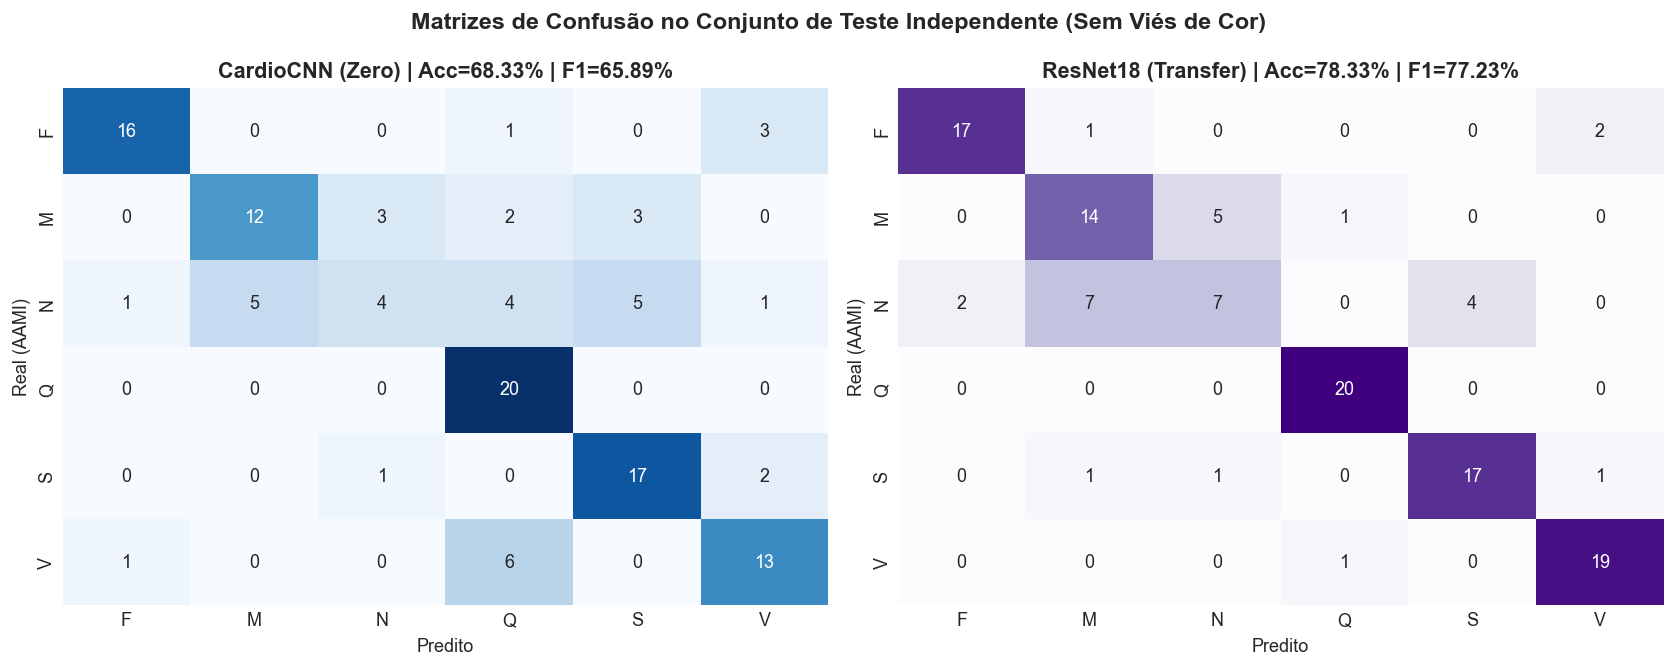

In [5]:
# Matrizes de Confusão lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(np.array(eval_cnn["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
axes[0].set_title(f"CardioCNN (Zero) | Acc={eval_cnn['accuracy']*100:.2f}% | F1={eval_cnn['f1_macro']*100:.2f}%", fontweight="bold")
axes[0].set_xlabel("Predito"); axes[0].set_ylabel("Real (AAMI)")

sns.heatmap(np.array(eval_res["confusion_matrix"]), annot=True, fmt="d", cmap="Purples",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False)
axes[1].set_title(f"ResNet18 (Transfer) | Acc={eval_res['accuracy']*100:.2f}% | F1={eval_res['f1_macro']*100:.2f}%", fontweight="bold")
axes[1].set_xlabel("Predito"); axes[1].set_ylabel("Real (AAMI)")

plt.suptitle("Matrizes de Confusão no Conjunto de Teste Independente (Sem Viés de Cor)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
            

---
## 4. Explicabilidade Clínica com Grad-CAM e Protótipo Interativo de Inferência

Aplicamos **Grad-CAM** na última camada convolucional da `ResNet18` (`layer4[-1].conv2`) para verificar visualmente se a rede concentra atenção nos picos **QRS**, ondas **P/T** e segmento **ST**, e demonstramos o motor de inferência `CardioPredictor` que também alimenta a interface web Flask (`Fase4/backend/app.py`) e o aplicativo mobile em React Native (`Fase4/mobile/App.js`).
            

[F0.png      ] Real=F -> Pred=F (Batimento de Fusão Ventricular        ) | Conf= 90.1% | Risco=ALTO     | 378.0 ms
[M152.png    ] Real=M -> Pred=N (Batimento Sinusal Normal              ) | Conf= 95.5% | Risco=BAIXO    | 364.3 ms
[N1906.png   ] Real=N -> Pred=S (Extrassístole Supraventricular        ) | Conf= 74.3% | Risco=MODERADO | 314.9 ms
[Q1360.png   ] Real=Q -> Pred=Q (Batimento de Marca-passo ou Inclassificável) | Conf= 99.0% | Risco=MODERADO | 299.7 ms
[S1852.png   ] Real=S -> Pred=M (Infarto do Miocárdio / Alteração Isquêmica) | Conf= 40.9% | Risco=CRITICO  | 346.6 ms
[V6468.png   ] Real=V -> Pred=V (Extrassístole Ventricular (PVC)       ) | Conf= 86.2% | Risco=ALTO     | 376.4 ms


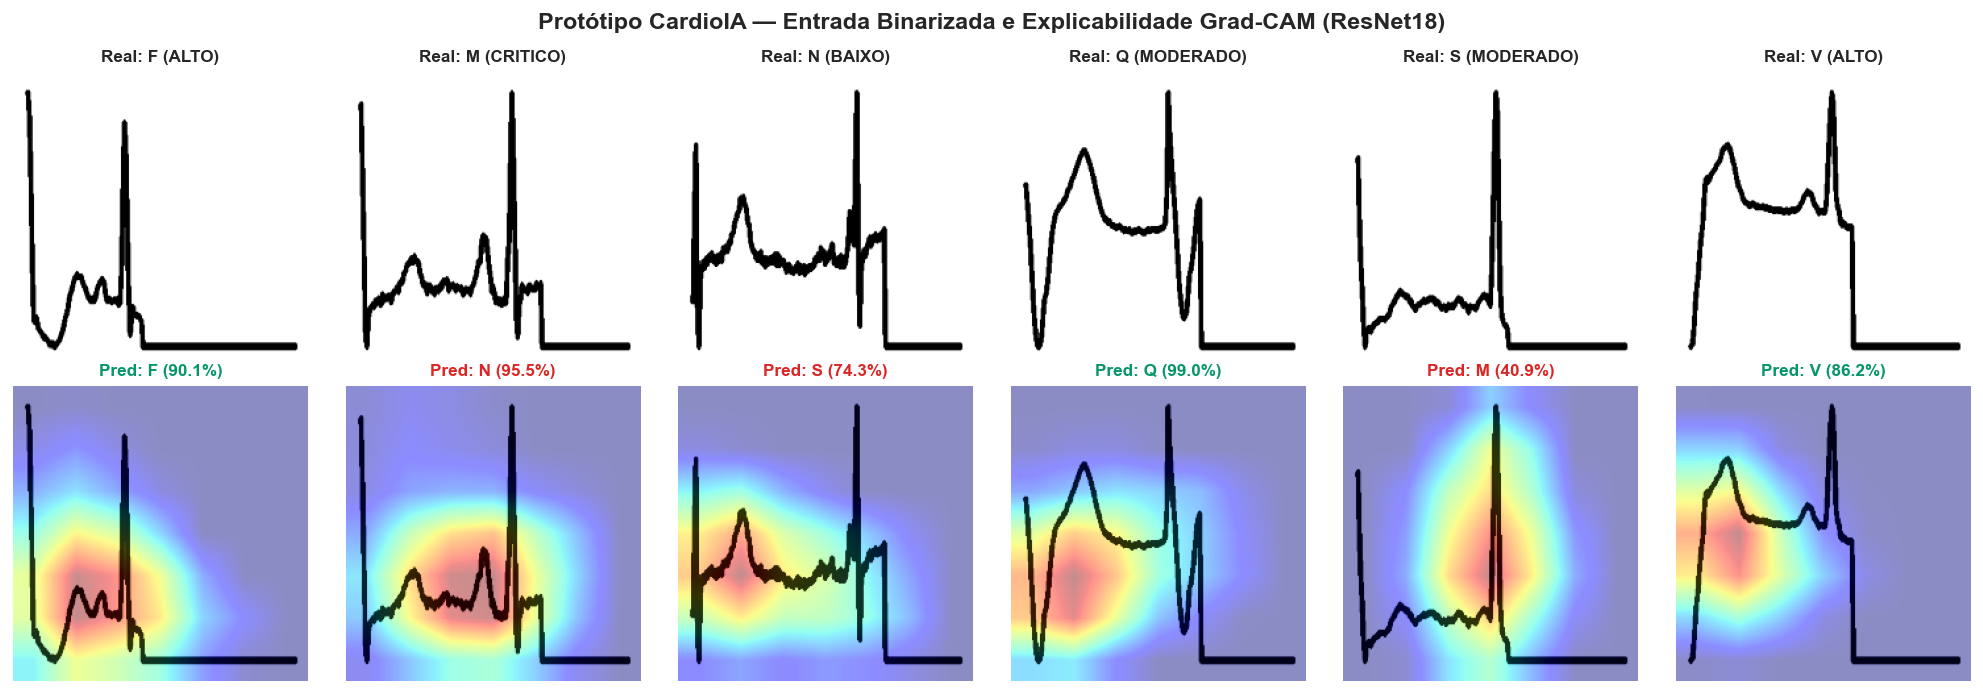

In [6]:
predictor = CardioPredictor(MODELS_DIR)

# Demonstração do Protótipo de Inferência Clínica em 6 exames do conjunto de teste (1 de cada classe)
fig, axes = plt.subplots(2, 6, figsize=(15.5, 5.4))
for i, cls in enumerate(CLASSES):
    sample_path = te_df[te_df["label"] == cls].iloc[0]["abs_path"]
    res = predictor.predict(sample_path, model_key="resnet18_transfer", include_gradcam=True)

    # Decodifica imagens retornadas pelo protótipo
    import base64, io
    from PIL import Image
    pre_img = Image.open(io.BytesIO(base64.b64decode(res["preprocessed_image_b64"].split(",", 1)[1])))
    cam_img = Image.open(io.BytesIO(base64.b64decode(res["gradcam_image_b64"].split(",", 1)[1])))

    axes[0, i].imshow(pre_img)
    axes[0, i].set_title(f"Real: {cls} ({CLASS_INFO[cls]['risk_level']})", fontsize=9.5, fontweight="bold")
    axes[0, i].axis("off")

    cor = "#059669" if res["predicted_class"] == cls else "#dc2626"
    axes[1, i].imshow(cam_img)
    axes[1, i].set_title(f"Pred: {res['predicted_class']} ({res['confidence_pct']:.1f}%)", fontsize=9.5, fontweight="bold", color=cor)
    axes[1, i].axis("off")

    print(
        f"[{Path(sample_path).name:12s}] Real={cls} -> Pred={res['predicted_class']} "
        f"({res['class_name_pt']:38s}) | Conf={res['confidence_pct']:5.1f}% | Risco={res['risk_level']:8s} | {res['inference_time_ms']} ms"
    )

plt.suptitle("Protótipo CardioIA — Entrada Binarizada e Explicabilidade Grad-CAM (ResNet18)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
            